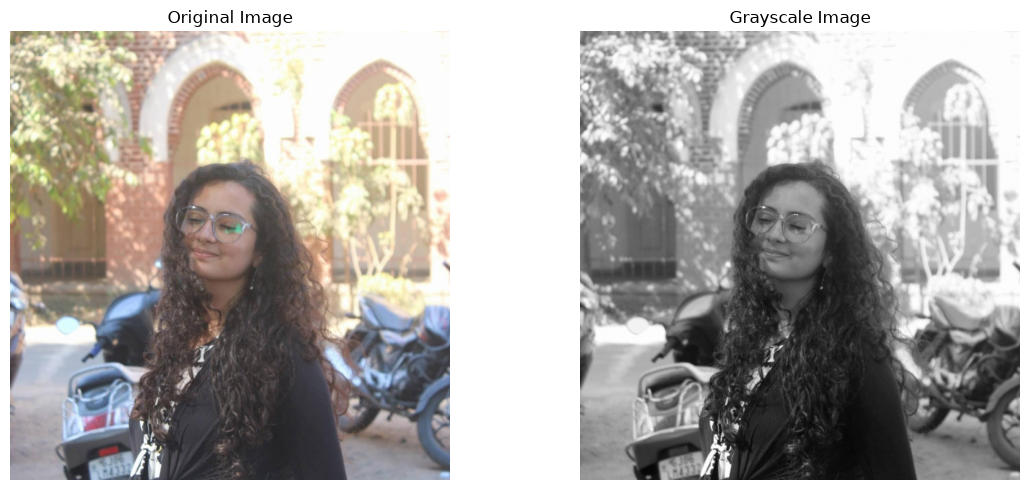

Image loaded successfully: (1304, 1279, 3)


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_path = Path("../data/images/original.jpeg")
image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path.resolve()}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image loaded successfully:", image.shape)


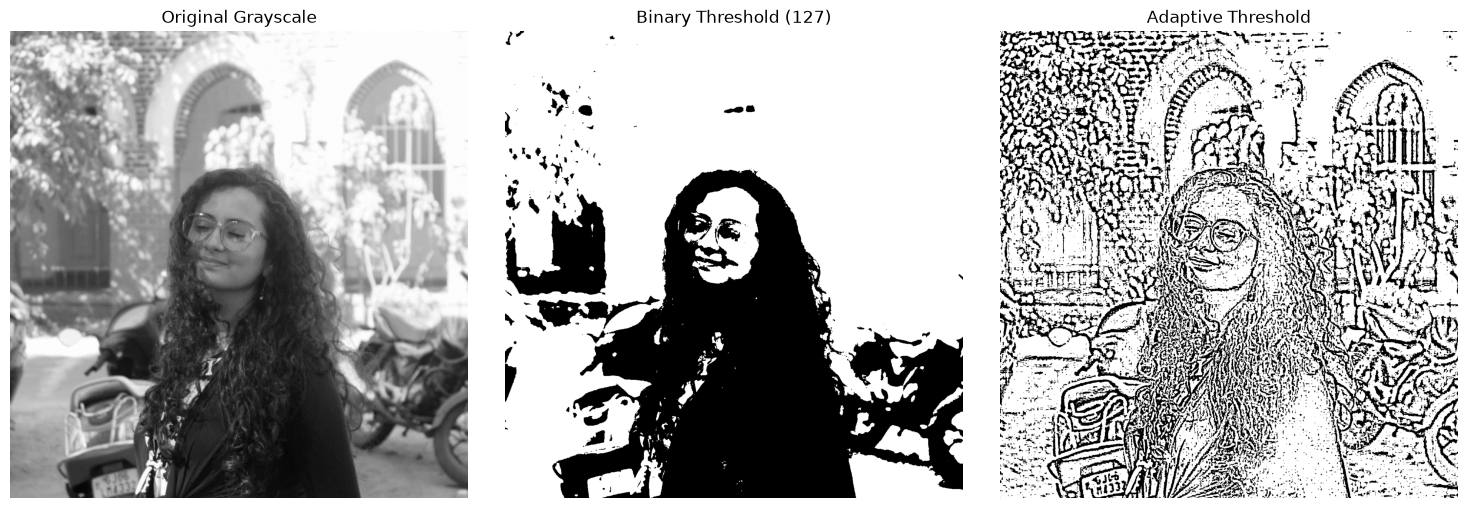

In [3]:
# Experiment 1: Binary and Adaptive Thresholding

# 1. Simple binary thresholding
threshold_value = 127

_, binary_threshold = cv2.threshold(
    gray, threshold_value, 255, cv2.THRESH_BINARY
)

# 2. Adaptive thresholding using the mean of local neighborhoods
adaptive_threshold = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11,  # Neighborhood size (must be odd)
    2    # Constant subtracted from the local mean
)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_threshold, cmap="gray")
plt.title("Binary Threshold (127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_threshold, cmap="gray")
plt.title("Adaptive Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
# Save thresholding results

output_dir = Path("../outputs/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(str(output_dir / "binary_threshold.png"), binary_threshold)
cv2.imwrite(str(output_dir / "adaptive_threshold.png"), adaptive_threshold)

print("Thresholding outputs saved successfully!")


Thresholding outputs saved successfully!


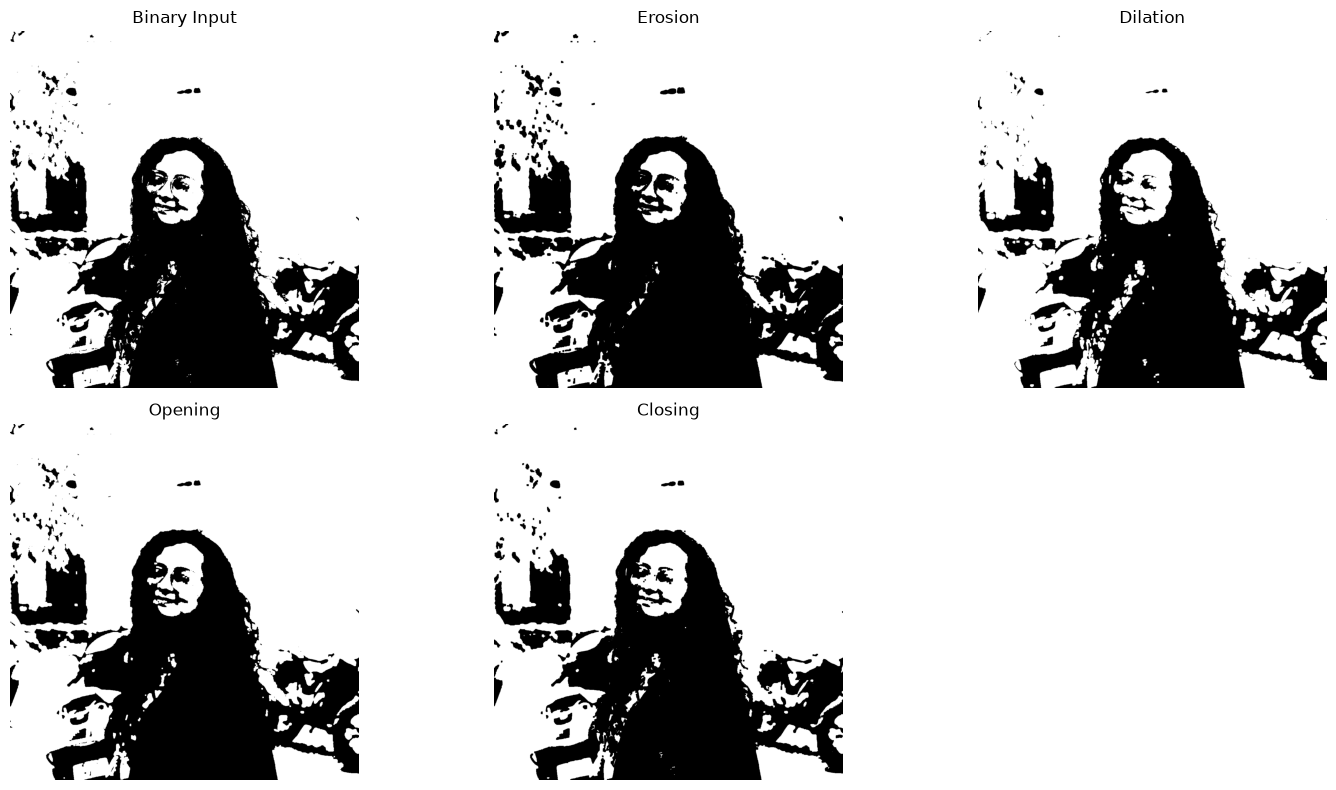

In [5]:
# Experiment 2: Morphological Operations

# Create a 5x5 structuring element
kernel = np.ones((5, 5), np.uint8)

# Apply morphological operations
erosion = cv2.erode(binary_threshold, kernel, iterations=1)
dilation = cv2.dilate(binary_threshold, kernel, iterations=1)

opening = cv2.morphologyEx(
    binary_threshold, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary_threshold, cv2.MORPH_CLOSE, kernel
)

# Display all results
results = [
    (binary_threshold, "Binary Input"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing"),
]

plt.figure(figsize=(15, 8))

for index, (result, title) in enumerate(results, start=1):
    plt.subplot(2, 3, index)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [6]:
# Save morphological operation outputs

morphology_results = {
    "erosion.png": erosion,
    "dilation.png": dilation,
    "opening.png": opening,
    "closing.png": closing,
}

output_dir = Path("../outputs/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

for filename, result in morphology_results.items():
    success = cv2.imwrite(str(output_dir / filename), result)
    print(f"{filename}: {'Saved' if success else 'Save failed'}")


erosion.png: Saved
dilation.png: Saved
opening.png: Saved
closing.png: Saved


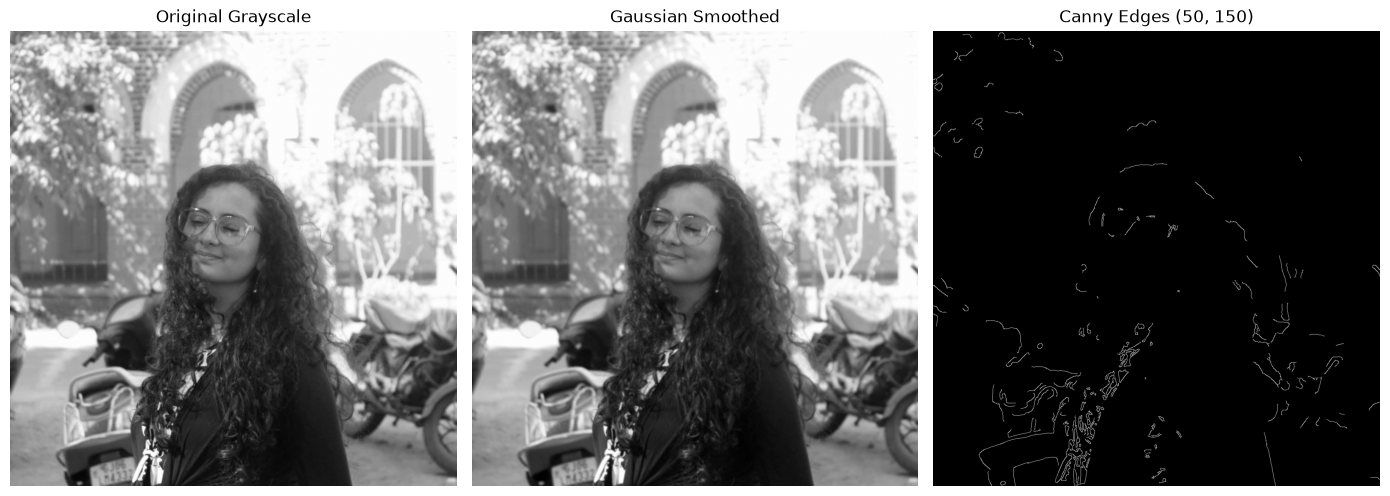

In [7]:
# Experiment 3: Canny Edge Detection

# Apply Gaussian smoothing before edge detection
blurred_gray = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
canny_edges = cv2.Canny(
    blurred_gray,
    threshold1=50,
    threshold2=150
)

# Display the results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_gray, cmap="gray")
plt.title("Gaussian Smoothed")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edges (50, 150)")
plt.axis("off")

plt.tight_layout()
plt.show()


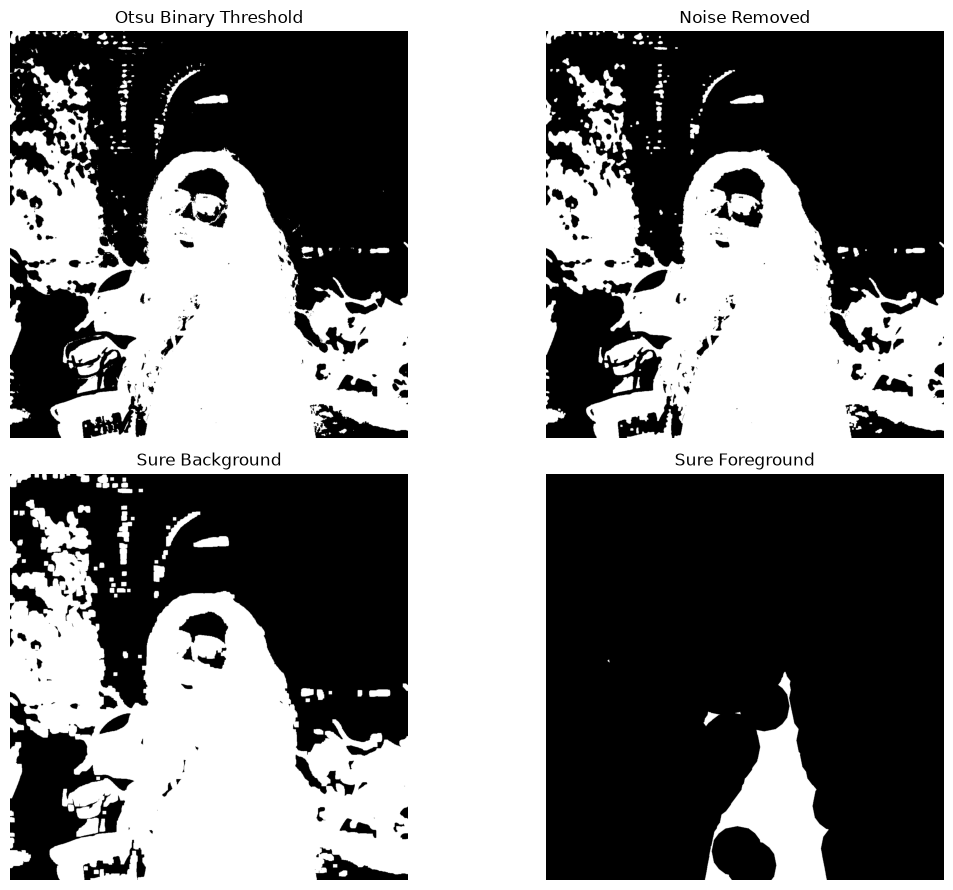

In [8]:
# Experiment 4: Watershed Segmentation

# Create a binary image using Otsu's thresholding
_, otsu_binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise using opening
kernel = np.ones((3, 3), np.uint8)
opening_ws = cv2.morphologyEx(
    otsu_binary, cv2.MORPH_OPEN, kernel, iterations=2
)

# Identify the sure background by expanding the foreground
sure_bg = cv2.dilate(opening_ws, kernel, iterations=3)

# Identify the sure foreground using a distance transform
distance = cv2.distanceTransform(opening_ws, cv2.DIST_L2, 5)

_, sure_fg = cv2.threshold(
    distance,
    0.4 * distance.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = sure_fg.astype(np.uint8)

# Identify uncertain regions
unknown = cv2.subtract(sure_bg, sure_fg)

# Display the intermediate results
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

images = [
    (otsu_binary, "Otsu Binary Threshold"),
    (opening_ws, "Noise Removed"),
    (sure_bg, "Sure Background"),
    (sure_fg, "Sure Foreground"),
]

for ax, (img, title) in zip(axes.flat, images):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


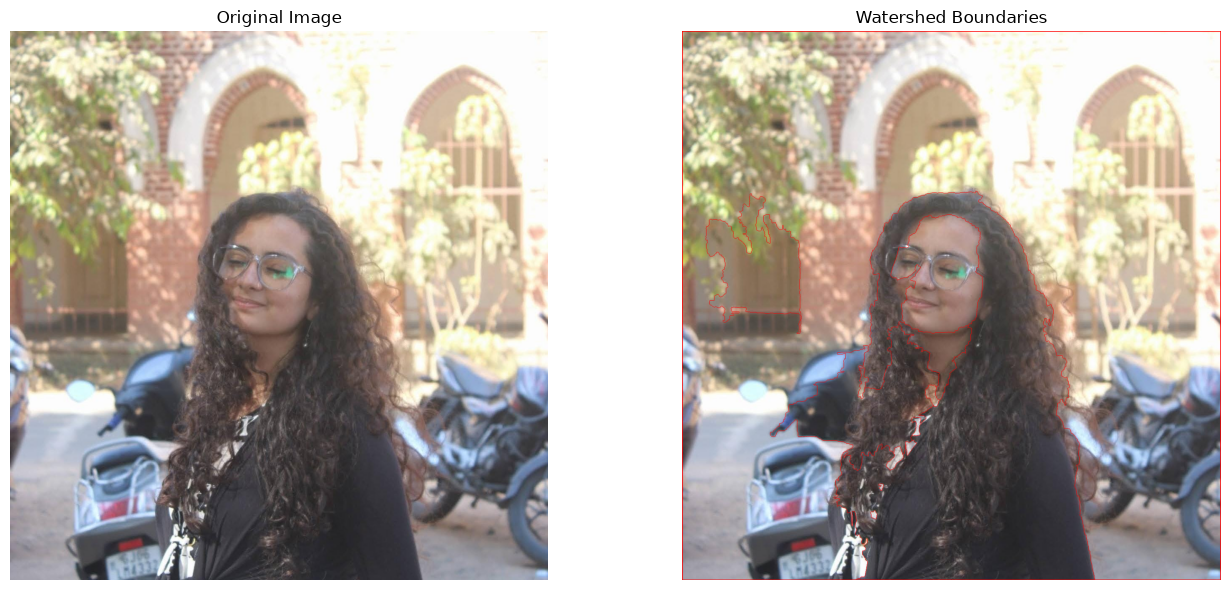

Watershed segmentation completed.
Foreground components detected: 4


In [9]:
# Label the foreground components
num_labels, markers = cv2.connectedComponents(sure_fg)

# Shift labels so that the background is not labeled as zero
markers = markers + 1

# Mark uncertain regions as zero
markers[unknown == 255] = 0

# Apply watershed
watershed_markers = cv2.watershed(image.copy(), markers)

# Highlight watershed boundaries in red
watershed_result = image.copy()
watershed_result[watershed_markers == -1] = [0, 0, 255]

# Display the result
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Watershed segmentation completed.")
print("Foreground components detected:", num_labels - 1)


In [10]:
output_dir = Path("../outputs/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "watershed_boundaries.png"),
    watershed_result
)

cv2.imwrite(
    str(output_dir / "watershed_foreground.png"),
    sure_fg
)

print("Watershed outputs saved successfully!")


Watershed outputs saved successfully!
